# 1. Imports & Configuration
Configure the dataset and the experiment models you want to test.
Set to "reben" for MAE pretrain reconstruction, or any downstream dataset for segmentation.


In [34]:
%load_ext autoreload
%autoreload 2
import sys
import os
sys.path.insert(0, os.path.abspath('../'))

import torch
import matplotlib.pyplot as plt
from hydra import compose, initialize

import albumentations as A
from albumentations.pytorch import ToTensorV2

from utils.utils import get_checkpoints_dir, find_best_ckpt
from utils.visualization import quant_norm, plot_images

DATASET_NAME = "c2seg_augsburg"  # "cashew_plantation", "reben_7k", "mmhunan", "c2seg_augsburg", "c2seg_beijing"
EXPERIMENTS = ["baseline", "feat_guided", "glcm_loss"]
SEED = 42

SAMPLE_IDX = 10
# for c2seg
CROP_SIZE = 512
CROP_POS_Y = 1300
CROP_POS_X = 200
if DATASET_NAME.startswith("c2seg"): SAMPLE_IDX = 0
#

MODE = "pretrain" if DATASET_NAME == "reben" else "finetune"

with initialize(version_base="1.3", config_path="../configs"):
    if MODE == "finetune":
        cfg = compose(config_name="finetune", overrides=[f"segmentation_ds={DATASET_NAME}", "paths=local"])
    else:
        cfg = compose(config_name="pretrain", overrides=["paths=local"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 2. Find Checkpoints & Load Models
Resolves the artifact directory for each experiment and loads the respective model weights.

In [35]:
print(f"Loading Models for {MODE}...")

runs_json = f"../{cfg.runs_json}" if not os.path.isabs(cfg.runs_json) else cfg.runs_json
artifacts_dir = f"../{cfg.paths.artifacts_dir}" if not os.path.isabs(cfg.paths.artifacts_dir) else cfg.paths.artifacts_dir

models = {}
for exp_name in EXPERIMENTS:
    exp_dir = get_checkpoints_dir(f"{exp_name}-{SEED}", DATASET_NAME, artifacts_dir, json_path=runs_json)
    ckpt_path = find_best_ckpt(exp_dir)
    if not ckpt_path: raise FileNotFoundError(f"No checkpoint found in {exp_dir}")
    print(f"[{exp_name}] Checkpoint: {ckpt_path.absolute()}")
    
    if MODE == "finetune":
        from hydra.utils import instantiate
        from utils.config import SegmentationViT_Cfg
        from dataclasses import asdict
        from models.segmentation.segmentation_vit import SegmentationViT
        
        model_cfg = SegmentationViT_Cfg(**{**dict(cfg.model), "norm_layer": instantiate(cfg.model.norm_layer)})
        model = SegmentationViT(**asdict(model_cfg))
        
        state = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        model.load_state_dict({k.removeprefix("model."): v for k, v in state.get("state_dict", state).items()})
        models[exp_name] = model.to(device).eval()
        
    else:
        from train.lightning_modules.mae_module import MAEModule
        model = MAEModule.load_from_checkpoint(ckpt_path, map_location=device).model
        models[exp_name] = model.to(device).eval()


Loading Models for finetune...
[baseline] Checkpoint: /mnt/ssd/.FINISHED_RUNS/RS_MAE-Thesis/nemr4k2j/checkpoints/seg-epoch=80-val_iou=0.2295.ckpt
[feat_guided] Checkpoint: /mnt/ssd/.FINISHED_RUNS/RS_MAE-Thesis/olajzzm9/checkpoints/seg-epoch=80-val_iou=0.2310.ckpt
[glcm_loss] Checkpoint: /mnt/ssd/.FINISHED_RUNS/RS_MAE-Thesis/z37ir6od/checkpoints/seg-epoch=85-val_iou=0.2312.ckpt


# 3. Load Dataset & Run Inference
Loads the target sample and runs all loaded models over the input batch. 
Automatically delegates to windowed inference for large crops.


In [36]:
print("Running Inference...")

if MODE == "finetune":
    from datasets import CashewPlantationDataset, C2SegDataset, MMHunanDataset, ReBEN7kDataset, Sen1Floods11Dataset, BurnScarsDataset
    from utils.config import CashewPlantationDataset_Cfg, C2SegDataset_Cfg, MMHunanDataset_Cfg, ReBEN7kDataset_Cfg, Sen1Floods11Dataset_Cfg, BurnScarsDataset_Cfg
    
    match cfg.dataset_name:
        case "reben_7k": dataset_class, dataset_class_cfg = ReBEN7kDataset, ReBEN7kDataset_Cfg
        case "sen1floods11": dataset_class, dataset_class_cfg = Sen1Floods11Dataset, Sen1Floods11Dataset_Cfg
        case "burn_scars": dataset_class, dataset_class_cfg = BurnScarsDataset, BurnScarsDataset_Cfg
        case "cashew_plantation": dataset_class, dataset_class_cfg = CashewPlantationDataset, CashewPlantationDataset_Cfg
        case "mmhunan": dataset_class, dataset_class_cfg = MMHunanDataset, MMHunanDataset_Cfg
        case name if name.startswith("c2seg"):
            dataset_class, dataset_class_cfg = C2SegDataset, C2SegDataset_Cfg
            if cfg.dataset_name == "c2seg_beijing": cfg.dataset_name, cfg.dataset.city = "c2seg_wuhan", "wuhan"
            elif cfg.dataset_name == "c2seg_augsburg": cfg.dataset_name, cfg.dataset.city = "c2seg_berlin", "berlin"
        case _: raise ValueError(f"Unsupported dataset: {cfg.dataset_name}")
        
    dataset_cfg = dataset_class_cfg(**cfg.dataset)
    for path_key in ["split_file", "keys_path", "data_dir"]:
        if hasattr(dataset_cfg, path_key) and getattr(dataset_cfg, path_key):
            val = getattr(dataset_cfg, path_key)
            if not os.path.isabs(val) and not val.startswith("../"):
                setattr(dataset_cfg, path_key, f"../{val}")
                
    from dataclasses import asdict
    dataset_kwargs = {**asdict(dataset_cfg), "grid_sampling": False}
    
    use_margin_crop = False
    if cfg.dataset_name.startswith("c2seg"):
        transform = A.Compose([ToTensorV2()])
        dataset = dataset_class(**dataset_kwargs, split="test", transform=transform)
        full_img, full_mask = dataset[SAMPLE_IDX]
        
        _, H_full, W_full = full_img.shape
        y_start = max(0, CROP_POS_Y - CROP_SIZE // 2)
        y_end = min(H_full, CROP_POS_Y + CROP_SIZE + CROP_SIZE // 2)
        x_start = max(0, CROP_POS_X - CROP_SIZE // 2)
        x_end = min(W_full, CROP_POS_X + CROP_SIZE + CROP_SIZE // 2)
        
        img_tensor = full_img[:, y_start:y_end, x_start:x_end]
        mask_tensor = full_mask[y_start:y_end, x_start:x_end]
        
        offset_y = CROP_POS_Y - y_start
        offset_x = CROP_POS_X - x_start
        use_margin_crop = True
    else:
        import cv2
        model_img_size = getattr(cfg.model, "img_size", 224)
        transform = A.Compose([
            A.PadIfNeeded(min_height=model_img_size, min_width=model_img_size, border_mode=cv2.BORDER_REFLECT),
            ToTensorV2()
        ])
        dataset = dataset_class(**dataset_kwargs, split="test", transform=transform)
        img_tensor, mask_tensor = dataset[SAMPLE_IDX]
        
    imgs_batch = img_tensor.unsqueeze(0).to(device)
    
else:
    from datasets import ReBENDataset
    dataset_cfg = cfg.dataset
    for path_key in ["split_file", "keys_path", "data_dir"]:
        val = dataset_cfg.get(path_key)
        if val and not os.path.isabs(val) and not val.startswith("../"):
            dataset_cfg[path_key] = f"../{val}"
            
    dataset = ReBENDataset(
        data_dir=dataset_cfg.data_dir,
        keys_path=dataset_cfg.keys_path,
        split="test", normalize=False, transform=A.Compose([ToTensorV2()])
    )
    img_tensor = dataset[SAMPLE_IDX][0] if isinstance(dataset[SAMPLE_IDX], tuple) else dataset[SAMPLE_IDX]
    imgs_batch = img_tensor.unsqueeze(0).to(device)


preds = {}
with torch.no_grad():
    for exp_name, model in models.items():
        if MODE == "finetune":
            H, W = imgs_batch.shape[2], imgs_batch.shape[3]
            model_img_size = getattr(cfg.model, "img_size", 224)
            
            if H > model_img_size or W > model_img_size:
                from utils.spatial_ops import windowed_inference
                pred_logits = windowed_inference(
                    model=model, image=imgs_batch, window_size=model_img_size,
                    stride=model_img_size // 2, num_classes=cfg.num_classes, 
                    batch_size=8, merger_device=device
                ).to(device)
            else:
                pred_logits = model(imgs_batch)
                
            pred_classes = torch.argmax(pred_logits, dim=1).squeeze(0).cpu().numpy()
            if use_margin_crop:
                preds[exp_name] = pred_classes[offset_y : offset_y + CROP_SIZE, offset_x : offset_x + CROP_SIZE]
            else:
                preds[exp_name] = pred_classes
        else:
            loss, pred, mask_expanded, _ = model(imgs_batch, mask_ratio=0.75, phase="validation")
            
            recon_pixels = model.target.restore(pred, gt_imgs=imgs_batch) if hasattr(model, "target") else pred
            if isinstance(recon_pixels, tuple): recon_pixels = recon_pixels[0]
                
            from utils.spatial_ops import unpatchify
            p = model.patch_embed.patch_size[0]
            B, _, H, W = imgs_batch.shape
            C = recon_pixels.shape[-1] // (p ** 2)
            preds[exp_name] = unpatchify(recon_pixels[..., :p*p*C], p, H, W, C)


Running Inference...


# 4. Plot Results
Display the original image alongside the models' predictions.


Plotting Results...


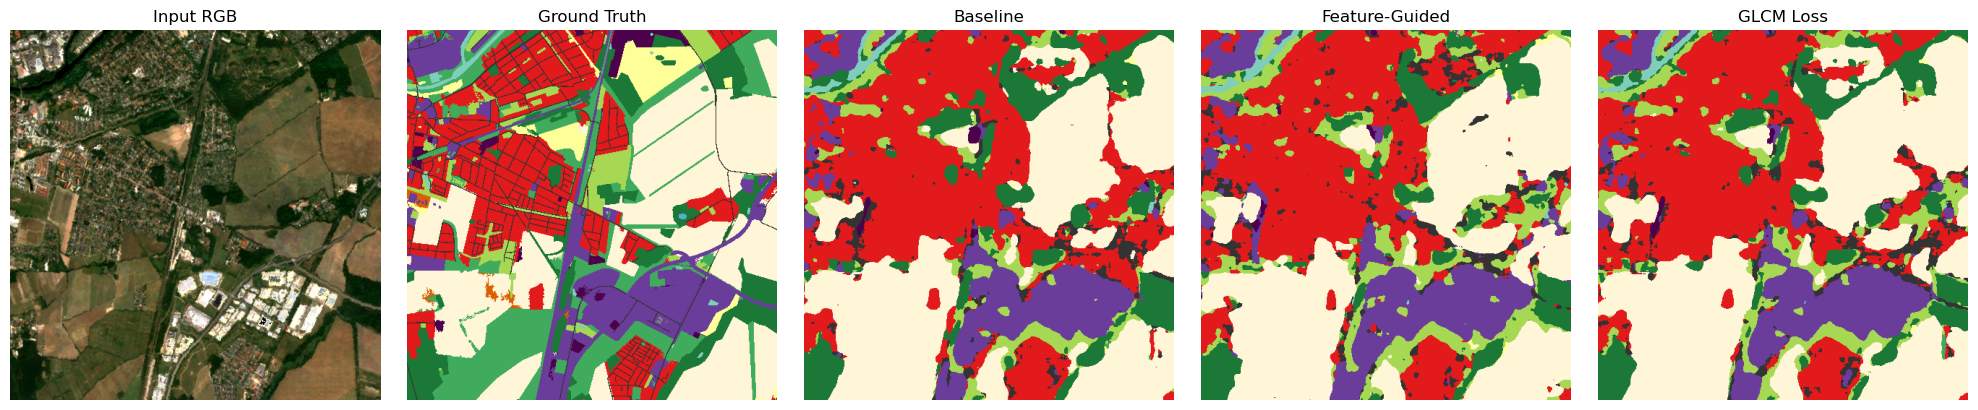

In [37]:
print("Plotting Results...")

if MODE == "finetune" and use_margin_crop:
    img_tensor = img_tensor[:, offset_y : offset_y + CROP_SIZE, offset_x : offset_x + CROP_SIZE]
    mask_tensor = mask_tensor[offset_y : offset_y + CROP_SIZE, offset_x : offset_x + CROP_SIZE]
    imgs_batch = img_tensor.unsqueeze(0).to(device)

true_color_bands = ["B04", "B03", "B02"]
if MODE == "finetune":
    bands = getattr(dataset_cfg, "bands", getattr(dataset, "bands", getattr(dataset, "BANDS", None)))
else:
    bands = getattr(dataset, "bands", getattr(dataset, "BANDS", None))
tc_idx = [bands.index(b) for b in true_color_bands if b in bands] if bands is not None else [0, 1, 2]

# Use joint normalization exactly as in prepare_segmentation_visuals
img_rgb = quant_norm(imgs_batch[:, tc_idx, :, :])[0].permute(1, 2, 0).cpu().numpy()

imgs_to_plot = [img_rgb]
titles = ["Input RGB"]

DISPLAY_NAMES = {
    "baseline": "Baseline", "curriculum_ndi": "Curriculum NDI",
    "feat_guided": "Feature-Guided", "latent_target": "Latent Target",
    "hog_weighted": "HOG-Weighted", "glcm_loss": "GLCM Loss",
    "curriculum_feat_unif": "Curriculum Feat Unif"
}

if MODE == "finetune":
    from utils.visualization import get_color_tensor
    color_tensor = get_color_tensor(dataset_name=cfg.dataset_name, max_id=cfg.num_classes)
    
    imgs_to_plot.append(color_tensor[mask_tensor.long()].numpy())
    titles.append("Ground Truth")
    
    for exp_name in EXPERIMENTS:
        imgs_to_plot.append(color_tensor[torch.from_numpy(preds[exp_name]).long()].numpy())
        titles.append(DISPLAY_NAMES.get(exp_name, exp_name))
        
    plot_images(imgs_to_plot, ncols=len(imgs_to_plot), img_titles=titles, size=4, dataset_name=cfg.dataset_name)

else:
    for exp_name in EXPERIMENTS:
        recon_rgb = quant_norm(preds[exp_name][:, tc_idx, :, :])[0].permute(1, 2, 0).cpu().numpy()
        imgs_to_plot.append(recon_rgb)
        titles.append(f"MAE Recon (75%)\n{DISPLAY_NAMES.get(exp_name, exp_name)}")
        
    plot_images(imgs_to_plot, ncols=len(imgs_to_plot), img_titles=titles, size=4, dataset_name=cfg.dataset_name)
